## Import main libs

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import time

## Loading dataset

In [2]:
path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
filename = "Suicide_Detection.csv"
df = pd.read_csv(f"{path}/{filename}")
df.head()

,Unnamed: 0,text,class
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide
1,3,Am I weird I don't get affected by compliments...,non-suicide
2,4,Finally 2020 is almost over... So I can never ...,non-suicide
3,8,i need helpjust help me im crying so hard,suicide
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide


# EDA

## main libs

In [3]:
import string
from collections import Counter, defaultdict
import emoji
from bidi.algorithm import get_display
import html
from nltk.corpus import stopwords
stop_words = stopwords.words('english')

## Cleaning the dataset

In [4]:

def clean_text_basic(text):
    """
    Clean text basic
    """
    if not isinstance(text, str):
        return ""

    text = text.lower()

    # removing special characters (keeping English, Arabic, and Hebrew letters)
    text = re.sub(r'[^\w\s\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF\uFB50-\uFDFF\uFE70-\uFEFF]', ' ', text)

    # removing extra spaces
    text = re.sub(r'\s+', ' ', text)

    # Remove spaces from the beginning and end
    text = text.strip()

    # Handle stop words - FIXED: text is a string, not a Series
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    text = ' '.join(filtered_words)

    return text


    return text

def normalize_persian_text(text):
    """
    Normaliation
    """
    # Nrmalize spaces and half-spaces(specialyy in persian texts)
    text = re.sub(r'[‌\u200c]', ' ', text)  # hlf-space -> normal space


    # Standardization of Persian letters
    text = text.replace('ي', 'ی')
    text = text.replace('ك', 'ک')
    text = text.replace('ة', 'ه')

    # حذف اعراب
    text = re.sub(r'[\u064B-\u065F]', '', text)  # Removing vowels
    return text

def remove_extra_whitespace(text):
    """
    Remove extra spaces
    """
    text = re.sub(r'\s+', ' ', text)  # Replacing multiple spaces with a single space
    text = re.sub(r'^\s+|\s+$', '', text)  # Remove spaces from the beginning and end
    return text

def remove_html_tags(text):
    """
    Removing html tags
    """
    return re.sub(r'<[^>]+>', '', text)

def remove_urls(text):
    """
    Removing urls
    """
    return re.sub(r'http\S+|www\.\S+', '', text)

def remove_emails(text):
    """
    Removing E-mails
    """
    return re.sub(r'\S+@\S+', '', text)

def remove_mentions_hashtags(text):
    """
    Removing mentions and hashtags
    """
    text = re.sub(r'@\w+', '', text)  # حذف mentions
    text = re.sub(r'#\w+', '', text)  # حذف hashtags
    return text

def remove_numbers(text, replace_with=''):
    """
    Replacing numbers
    """
    return re.sub(r'\d+', replace_with, text)

def remove_emoji(text):
    """
    Removing Emojies
    """
    return emoji.replace_emoji(text, replace='')

def correct_persian_spacing(text):
    """
    Correcting spacing in Persian text
    """
    # حرف اضافه‌های فارسی که باید به کلمه قبل بچسبند
    attached_prefixes = ['از', 'به', 'در', 'با', 'بر', 'برای', 'تا', 'بی', 'غیر']

    # حروف ربط که باید به کلمه بعد بچسبند
    attached_suffixes = ['ها', 'های', 'ترین', 'تری', 'ام', 'ات', 'اش']

    words = text.split()
    corrected_words = []

    for i, word in enumerate(words):
        if i > 0 and any(word.startswith(prefix) for prefix in attached_prefixes):
            corrected_words[-1] = corrected_words[-1] + ' ' + word
        elif i < len(words) - 1 and any(words[i+1].startswith(suffix) for suffix in attached_suffixes):
            corrected_words.append(word + ' ' + words[i+1])
        else:
            corrected_words.append(word)

    return ' '.join(corrected_words)

def advanced_text_cleaning(text, cleaning_options=None):
    """
    Advanced text cleaning with configurable options
    """
    if cleaning_options is None:
        cleaning_options = {
            'remove_html': True,
            'remove_urls': True,
            'remove_emails': True,
            'remove_mentions_hashtags': True,
            'remove_numbers': True,
            'remove_emoji': True,
            'normalize_persian': True,
            'correct_spacing': True,
            'remove_extra_whitespace': True
        }

    if not isinstance(text, str):
        return ""

    # Apply cleaning steps based on options
    if cleaning_options.get('remove_html', True):
        text = remove_html_tags(text)

    if cleaning_options.get('remove_urls', True):
        text = remove_urls(text)

    if cleaning_options.get('remove_emails', True):
        text = remove_emails(text)

    if cleaning_options.get('remove_mentions_hashtags', True):
        text = remove_mentions_hashtags(text)

    if cleaning_options.get('remove_numbers', True):
        text = remove_numbers(text)

    if cleaning_options.get('remove_emoji', True):
        text = remove_emoji(text)

    # Base cleaning
    text = clean_text_basic(text)

    if cleaning_options.get('normalize_persian', True):
        text = normalize_persian_text(text)

    if cleaning_options.get('correct_spacing', True):
        text = correct_persian_spacing(text)

    if cleaning_options.get('remove_extra_whitespace', True):
        text = remove_extra_whitespace(text)

    return text

# تابع اصلی برای پاکسازی و ارزیابی
def clean_and_evaluate_dataset(df, text_column, label_column, cleaning_options=None):

    print("Cleaning is started")

    df_clean = df.copy()

    df_clean['original_text'] = df_clean[text_column]

    df_clean['cleaned_text'] = df_clean[text_column].apply(
        lambda x: advanced_text_cleaning(x, cleaning_options)
    )

    original_lengths = df_clean['original_text'].str.len()
    cleaned_lengths = df_clean['cleaned_text'].str.len()

    print(f"Numbe of samples: {len(df_clean)}")
    print(f"Mean length of texts: {original_lengths.mean():.2f}")
    print(f"Mean length of cleaned texts: {cleaned_lengths.mean():.2f}")
    print(f"diff: {(cleaned_lengths.mean() - original_lengths.mean()):.2f}")

    print("\nSample of cleaning:")
    print("Orginal text:", df_clean['original_text'].iloc[0][:100] + "...")
    print("Cleaned text:", df_clean['cleaned_text'].iloc[0][:100] + "...")

    return df_clean

In [5]:
if __name__ == "__main__":
    df = df

    cleaning_config = {
      'remove_html': True,
      'remove_urls': True,
      'remove_emails': True,
      'remove_mentions_hashtags': False,
      'remove_numbers': False,
      'remove_emoji': False,
      'normalize_persian': False,
      'correct_spacing': True,
      'remove_extra_whitespace': True
    }

    # cleaning
    df_cleaned = clean_and_evaluate_dataset(
        df=df,
        text_column='text',
        label_column='class',
        cleaning_options=cleaning_config
    )


Cleaning is started
Numbe of samples: 232074
Mean length of texts: 689.64
Mean length of cleaned texts: 392.41
diff: -297.23

Sample of cleaning:
Orginal text: Ex Wife Threatening SuicideRecently I left my wife for good because she has cheated on me twice and ...
Cleaned text: ex wife threatening suiciderecently left wife good cheated twice lied much decided refuse go back da...


## Tokenization

In [6]:
def char_ngram_tokenizer(text, n=3):
    tokens = []
    for word in re.findall(r"\S+", text):
        w = f"<{word}>"
        if len(w) <= n:
            tokens.append(w)
        else:
            for i in range(len(w) - n + 1):
                tokens.append(w[i:i+n])
    return tokens

def whitespace_tokenizer(text):
    return text.split()

In [7]:
print("Tokenizing is started")

df_tokenized = df_cleaned.copy()

text_column='cleaned_text'
df_tokenized['class'] = df_tokenized['class'].map({'suicide': 1, 'non-suicide': 0})

df_tokenized['whitespace_tokenizer'] = df_tokenized[text_column].apply(
    lambda x: whitespace_tokenizer(x)
)
df_tokenized = df_tokenized.drop(['original_text', 'cleaned_text', 'text', 'Unnamed: 0'], axis=1)
df_tokenized.head()

Tokenizing is started


,class,whitespace_tokenizer
0,1,"[ex, wife, threatening, suiciderecently, left,..."
1,0,"[weird, get, affected, compliments, coming, so..."
2,0,"[finally, 2020, almost, never, hear, 2020, bad..."
3,1,"[need, helpjust, help, im, crying, hard]"
4,1,"[losthello, name, adam, 16, struggling, years,..."


## Visualazation

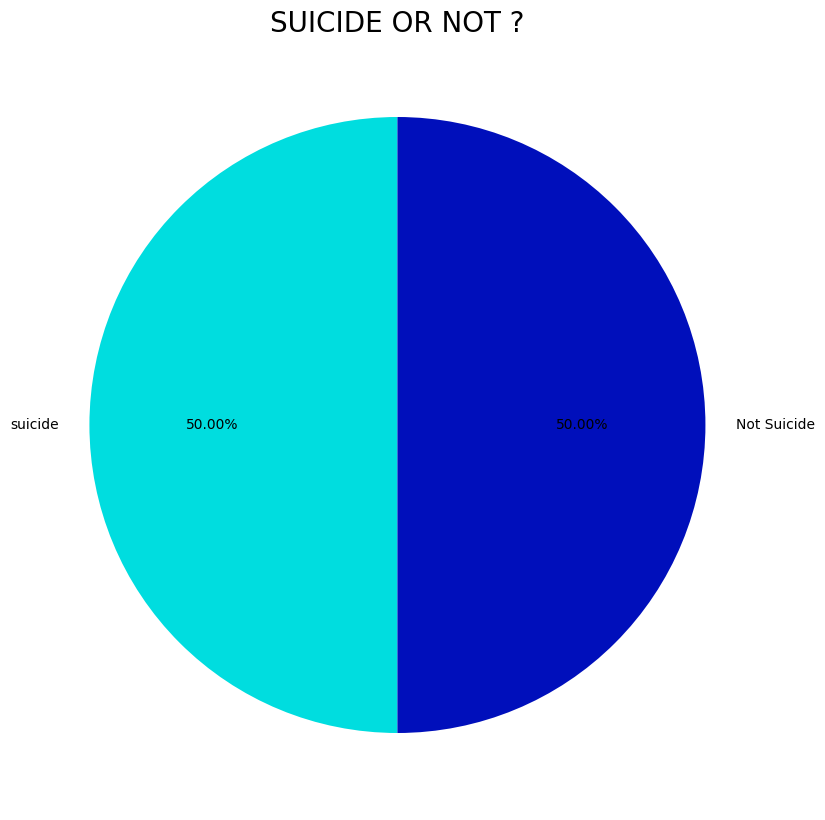

In [8]:
plt.figure(figsize=(12,10))
plt.pie(df_tokenized['class'].value_counts(),startangle=90,colors=['#00dddf','#000fbb'],
        autopct='%0.2f%%',labels=['suicide','Not Suicide'])
plt.title('SUICIDE OR NOT ?',fontdict={'size':20})
plt.show()

Number of rows: 116037


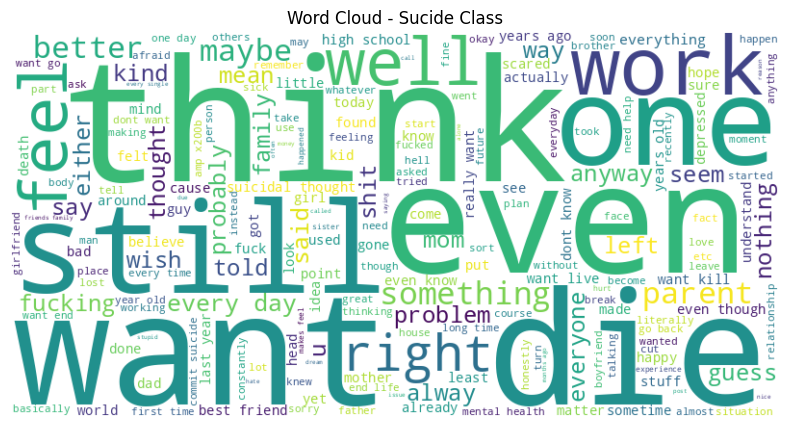

In [9]:
from wordcloud import WordCloud

class_normalized = (
    df_tokenized['class']
    .astype(str)
    .str.strip()
    .str.lower()
)

suicide_df = df_tokenized[class_normalized == '1']

print(f"Number of rows: {len(suicide_df)}")

# Join texts
all_text = ' '.join(
    suicide_df['whitespace_tokenizer']
    .astype(str)
    .str.strip('[]')
    .str.replace("'", "", regex=False)
).strip()

# Check whether text exists
if not all_text:
    print("class Not found")
else:
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(all_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title('Word Cloud - Sucide Class')
    plt.show()

## Vectorization

In [10]:
from sklearn.preprocessing import LabelEncoder
from gensim.models import Word2Vec

# Preprocess the token_text column
def preprocess_tokens(text_series):
    """Convert token_text list to string"""
    return text_series.astype(str).str.strip('[]').str.replace("'", "")

# Prepare the data
df_tokenized['processed_text'] = preprocess_tokens(df_tokenized['whitespace_tokenizer'])

# Encode the target variable
le = LabelEncoder()
df_tokenized['encoded_class'] = le.fit_transform(df_tokenized['class'])

print("Class mapping:")
for i, class_name in enumerate(le.classes_):
    print(f"{class_name}: {i}")

# ---------------------------------------------------------
# Word2Vec Vectorization
# ---------------------------------------------------------

print("Generating Word2Vec embeddings...")

# Convert each text into a list of tokens
sentences = [
    text.split()
    for text in df_tokenized['processed_text'].tolist()
]

# Train Word2Vec model
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    seed=42
)

# Create one fixed-size vector for each document
def document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0).astype(np.float32)

# Generate X with the same expected structure as before
X = np.vstack([
    document_vector(tokens, w2v_model)
    for tokens in sentences
])

print(f"Word2Vec Feature matrix shape: {X.shape}")

# Target variable
y = df_tokenized['encoded_class']

print(f"Target variable distribution:\n{df_tokenized['class'].value_counts()}")

Class mapping:
0: 0
1: 1
Generating Word2Vec embeddings...
Word2Vec Feature matrix shape: (232074, 100)
Target variable distribution:
class
1    116037
0    116037
Name: count, dtype: int64


# Models

## Main libs

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier,VotingClassifier,AdaBoostClassifier,GradientBoostingClassifier,BaggingClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

## Spliting the dataset

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Training set size: 185659
Test set size: 46415


## Random Forest

In [14]:
model2 = RandomForestClassifier()

start_time = time.time()

model2.fit(X_train, y_train)

training_time = time.time() - start_time

train_score = model2.score(X_train, y_train)
test_score = model2.score(X_test, y_test)

total_time = time.time() - start_time

print(f"Training Time: {training_time:.4f} seconds")
print(f"Train Accuracy: {train_score:.4f}")
print(f"Test Accuracy: {test_score:.4f}")
print(f"Total Execution Time: {total_time:.4f} seconds")

Training Time: 664.4159 seconds
Train Accuracy: 0.9999
Test Accuracy: 0.9231
Total Execution Time: 669.9107 seconds


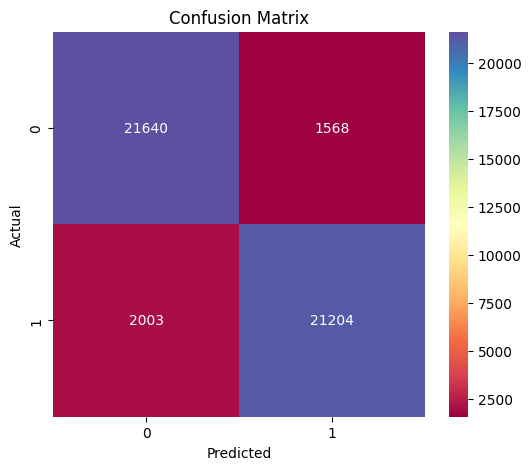

              precision    recall  f1-score   support

           0       0.92      0.93      0.92     23208
           1       0.93      0.91      0.92     23207

    accuracy                           0.92     46415
   macro avg       0.92      0.92      0.92     46415
weighted avg       0.92      0.92      0.92     46415


AUC (Binary): 0.9756909620

========== Model Performance ==========
Accuracy:        0.9230636648
Precision:       0.9232123232
Recall:          0.9230636648
Precision Macro: 0.9232124941
Recall Macro:    0.9230634628
F1 Score Macro:  0.9230568754


In [17]:
y_act = y_test
y_pred = model2.predict(X_test)

# --------------------------------------------------
# Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(y_act, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Spectral'
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# --------------------------------------------------
# Classification Report
# --------------------------------------------------

print(classification_report(y_act, y_pred))

# --------------------------------------------------
# Main Metrics
# --------------------------------------------------

accuracy = accuracy_score(y_act, y_pred)

precision = precision_score(
    y_act,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_act,
    y_pred,
    average='weighted'
)

precision_macro = precision_score(
    y_act,
    y_pred,
    average='macro'
)

recall_macro = recall_score(
    y_act,
    y_pred,
    average='macro'
)

f1score = f1_score(
    y_act,
    y_pred,
    average='macro'
)

# --------------------------------------------------
# AUC
# --------------------------------------------------

# Random Forest supports predict_proba
y_pred_proba = model2.predict_proba(X_test)

n_classes = len(np.unique(y_act))

if n_classes == 2:

    # Probability of the positive class
    y_score = y_pred_proba[:, 1]

    auc = roc_auc_score(
        y_act,
        y_score
    )

    print("\nAUC (Binary): {:.10f}".format(auc))

else:

    # Multi-class AUC
    auc_ovr = roc_auc_score(
        y_act,
        y_pred_proba,
        average='macro',
        multi_class='ovr'
    )

    auc_ovo = roc_auc_score(
        y_act,
        y_pred_proba,
        average='macro',
        multi_class='ovo'
    )

    print("\nAUC (One-vs-Rest, macro): {:.10f}".format(auc_ovr))
    print("AUC (One-vs-One, macro): {:.10f}".format(auc_ovo))

# --------------------------------------------------
# Print Metrics
# --------------------------------------------------

print("\n========== Model Performance ==========")
print("Accuracy:        {:.10f}".format(accuracy))
print("Precision:       {:.10f}".format(precision))
print("Recall:          {:.10f}".format(recall))
print("Precision Macro: {:.10f}".format(precision_macro))
print("Recall Macro:    {:.10f}".format(recall_macro))
print("F1 Score Macro:  {:.10f}".format(f1score))

### Best Treshhold

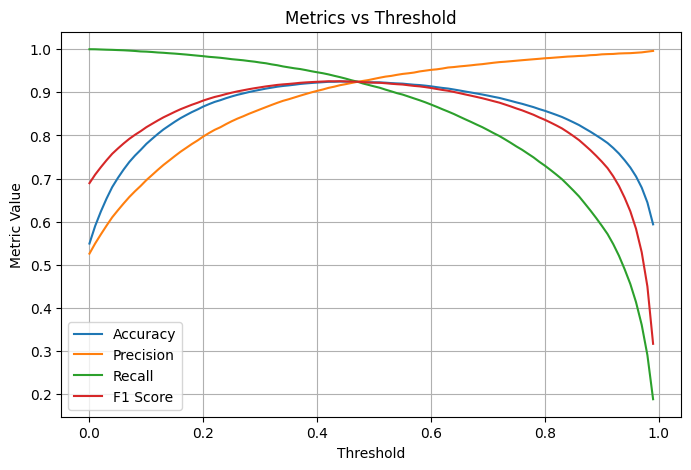

In [18]:
y_act = y_test
prob = model2.predict_proba(X_test)

alphas = np.arange(0.0, 1.0, 0.01)

accuracies = []
precisions = []
recalls = []
f1s = []

for alpha in alphas:
    y_pred = [1 if p[1] > alpha else 0 for p in prob]

    accuracies.append(accuracy_score(y_act, y_pred))
    precisions.append(precision_score(y_act, y_pred, zero_division=0))
    recalls.append(recall_score(y_act, y_pred, zero_division=0))
    f1s.append(f1_score(y_act, y_pred, zero_division=0))

plt.figure(figsize=(8,5))

plt.plot(alphas, accuracies, label="Accuracy")
plt.plot(alphas, precisions, label="Precision")
plt.plot(alphas, recalls, label="Recall")
plt.plot(alphas, f1s, label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("Metric Value")
plt.title("Metrics vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

              precision    recall  f1-score   support

           0       0.92      0.93      0.92     23208
           1       0.93      0.92      0.92     23207

    accuracy                           0.92     46415
   macro avg       0.92      0.92      0.92     46415
weighted avg       0.92      0.92      0.92     46415

precision_macro: 0.9236399592456629
recall_macro: 0.9236237620910033
accuracy: 0.9236238285037165
precision: 0.923639903040987
recall: 0.9236238285037165
f1score: 0.9236230933632331


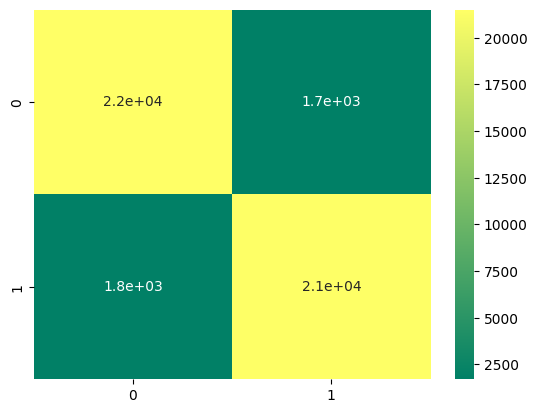

In [19]:
y_act=y_test
#y_pred=VotingClassifiers.predict(X_test)
y_pred = []
prob = model2.predict_proba(X_test)
counter = 0
alpha = 0.48
for p in prob:
    if p[1] > alpha:
        y_pred.append(1)
    else:
        y_pred.append(0)
    counter = counter+1
sns.heatmap(confusion_matrix(y_act,y_pred),annot=True,cmap='summer')
print(classification_report(y_act,y_pred))

# For multi-class classification
accuracy = accuracy_score(y_act, y_pred)
precision = precision_score(y_act, y_pred, average='weighted')
recall = recall_score(y_act, y_pred, average='weighted')
f1score = f1_score(y_act, y_pred, average='macro')

# Or for macro average (treats all classes equally)
precision_macro = precision_score(y_act, y_pred, average='macro')
recall_macro = recall_score(y_act, y_pred, average='macro')

print("precision_macro: {}".format(precision_macro))
print("recall_macro: {}".format(recall_macro))

print("accuracy: {}".format(accuracy))
print("precision: {}".format(precision))
print("recall: {}".format(recall))
print("f1score: {}".format(f1score))

## Decision Tree

### Cross Validation

In [21]:
model = DecisionTreeClassifier(random_state=0)

param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20, 30, 50, 70, 100],
    'min_samples_leaf': [1, 5, 10, 20, 30, 50, 70, 100],
    'max_features': [None, 'sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

start_time = time.time()

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    scoring='recall',
    cv=3,
    random_state=0,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

search_time = time.time() - start_time

print("Best Parameters:")
print(search.best_params_)

print("\nBest CV Score:")
print(search.best_score_)

print(f"\nSearch Time: {search_time:.4f} seconds")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 10, 'criterion': 'entropy', 'class_weight': None}

Best CV Score:
0.9033825203313031

Search Time: 291.7087 seconds


Training Time: 2.1023 seconds
0.8778513295881158
0.8715070559086502
Total Execution Time: 2.1023 seconds
              precision    recall  f1-score   support

           0       0.87      0.87      0.87     23208
           1       0.87      0.87      0.87     23207

    accuracy                           0.87     46415
   macro avg       0.87      0.87      0.87     46415
weighted avg       0.87      0.87      0.87     46415


AUC (Binary): 0.9756909620

========== Model Performance ==========
Accuracy:        0.8715070559
Precision:       0.8715198307
Recall:          0.8715070559
Precision Macro: 0.8715197838
Recall Macro:    0.8715071190
F1 Score Macro:  0.8715059689


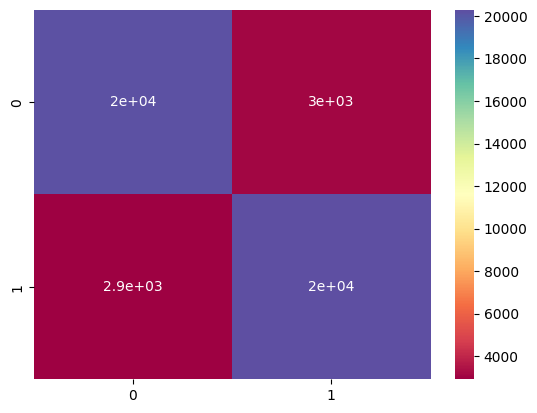

In [23]:
model3 = DecisionTreeClassifier(criterion='entropy',splitter='random',min_samples_split=2 ,min_samples_leaf=1,max_depth=10,class_weight=None)

start_time = time.time()

model3.fit(X_train, y_train)

training_time = time.time() - start_time
total_time = time.time() - start_time

print(f"Training Time: {training_time:.4f} seconds")
print(model3.score(X_train, y_train))
print(model3.score(X_test,y_test))
print(f"Total Execution Time: {total_time:.4f} seconds")

y_act=y_test
y_pred=model3.predict(X_test)
sns.heatmap(confusion_matrix(y_act,y_pred),annot=True,cmap='Spectral')
print(classification_report(y_act,y_pred))

accuracy = accuracy_score(y_act, y_pred)
precision = precision_score(y_act, y_pred, average='weighted')
recall = recall_score(y_act, y_pred, average='weighted')

precision_macro = precision_score(y_act, y_pred, average='macro')
recall_macro = recall_score(y_act, y_pred, average='macro')
f1score = f1_score(y_act, y_pred, average='macro')
auc = auc = roc_auc_score(y_act, y_score)

print("\nAUC (Binary): {:.10f}".format(auc))

print("\n========== Model Performance ==========")
print("Accuracy:        {:.10f}".format(accuracy))
print("Precision:       {:.10f}".format(precision))
print("Recall:          {:.10f}".format(recall))
print("Precision Macro: {:.10f}".format(precision_macro))
print("Recall Macro:    {:.10f}".format(recall_macro))
print("F1 Score Macro:  {:.10f}".format(f1score))

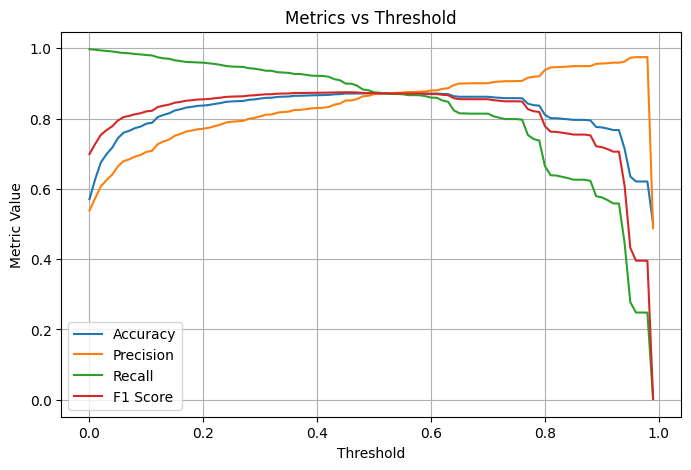

In [24]:
y_act = y_test
prob = model3.predict_proba(X_test)

alphas = np.arange(0.0, 1.0, 0.01)

accuracies = []
precisions = []
recalls = []
f1s = []

for alpha in alphas:
    y_pred = [1 if p[1] > alpha else 0 for p in prob]

    accuracies.append(accuracy_score(y_act, y_pred))
    precisions.append(precision_score(y_act, y_pred, zero_division=0))
    recalls.append(recall_score(y_act, y_pred, zero_division=0))
    f1s.append(f1_score(y_act, y_pred, zero_division=0))

plt.figure(figsize=(8,5))

plt.plot(alphas, accuracies, label="Accuracy")
plt.plot(alphas, precisions, label="Precision")
plt.plot(alphas, recalls, label="Recall")
plt.plot(alphas, f1s, label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("Metric Value")
plt.title("Metrics vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

## XG-Boost

In [25]:
model = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1, 0.2]
}

start_time = time.time()

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search.fit(X_train, y_train)

training_time = time.time() - start_time

print("Best Parameters:")
print(random_search.best_params_)

print(f"\nBest CV Accuracy: {random_search.best_score_:.4f}")

best_model = random_search.best_estimator_

train_score = best_model.score(X_train, y_train)
test_score = best_model.score(X_test, y_test)

print(f"Train Accuracy: {train_score:.4f}")
print(f"Test Accuracy: {test_score:.4f}")
print(f"Training Time: {training_time:.4f} seconds")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'n_estimators': 150, 'max_depth': 10, 'learning_rate': 0.2}

Best CV Accuracy: 0.9344
Train Accuracy: 0.9998
Test Accuracy: 0.9363
Training Time: 276.4495 seconds


In [26]:
model4 = XGBClassifier( eval_metric='map',max_depth=10,n_estimators=150,learning_rate=0.2)

start_time = time.time()

model4.fit(X_train, y_train)

training_time = time.time() - start_time
total_time = time.time() - start_time

print(f"Training Time: {training_time:.4f} seconds")
print(model4.score(X_train, y_train))
print(model4.score(X_test,y_test))
print(f"Total Execution Time: {total_time:.4f} seconds")

Training Time: 37.9753 seconds
0.999784551247179
0.9363136916944953
Total Execution Time: 37.9753 seconds


              precision    recall  f1-score   support

           0       0.94      0.94      0.94     23208
           1       0.94      0.94      0.94     23207

    accuracy                           0.94     46415
   macro avg       0.94      0.94      0.94     46415
weighted avg       0.94      0.94      0.94     46415


AUC (Binary): 0.9756909620

========== Model Performance ==========
Accuracy:        0.9363136917
Precision:       0.9363140825
Recall:          0.9363136917
Precision Macro: 0.9363140914
Recall Macro:    0.9363136815
F1 Score Macro:  0.9363136761


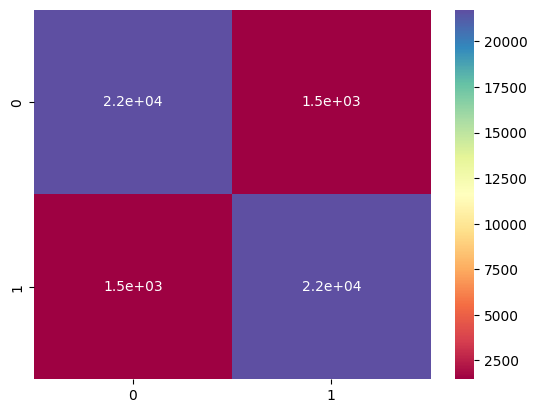

In [27]:
y_act=y_test
y_pred=model4.predict(X_test)
sns.heatmap(confusion_matrix(y_act,y_pred),annot=True,cmap='Spectral')
print(classification_report(y_act,y_pred))

# For multi-class classification
accuracy = accuracy_score(y_act, y_pred)
precision = precision_score(y_act, y_pred, average='weighted')
recall = recall_score(y_act, y_pred, average='weighted')

# Or for macro average (treats all classes equally)
precision_macro = precision_score(y_act, y_pred, average='macro')
recall_macro = recall_score(y_act, y_pred, average='macro')
f1score = f1_score(y_act, y_pred, average='macro')
auc = auc = roc_auc_score(y_act, y_score)

print("\nAUC (Binary): {:.10f}".format(auc))

print("\n========== Model Performance ==========")
print("Accuracy:        {:.10f}".format(accuracy))
print("Precision:       {:.10f}".format(precision))
print("Recall:          {:.10f}".format(recall))
print("Precision Macro: {:.10f}".format(precision_macro))
print("Recall Macro:    {:.10f}".format(recall_macro))
print("F1 Score Macro:  {:.10f}".format(f1score))

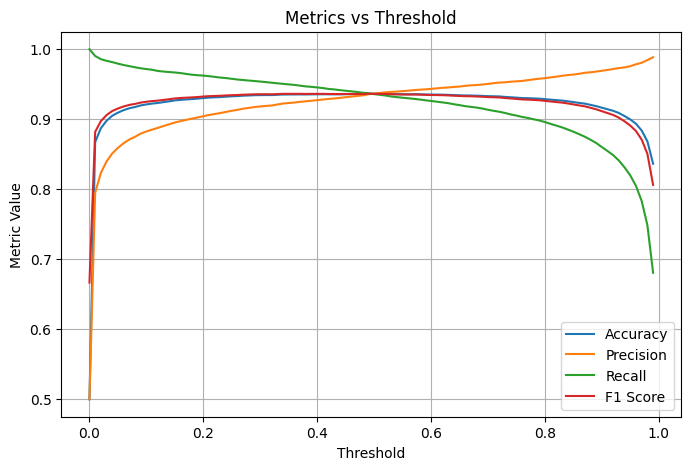

In [28]:
y_act = y_test
prob = model4.predict_proba(X_test)

alphas = np.arange(0.0, 1.0, 0.01)

accuracies = []
precisions = []
recalls = []
f1s = []

for alpha in alphas:
    y_pred = [1 if p[1] > alpha else 0 for p in prob]

    accuracies.append(accuracy_score(y_act, y_pred))
    precisions.append(precision_score(y_act, y_pred, zero_division=0))
    recalls.append(recall_score(y_act, y_pred, zero_division=0))
    f1s.append(f1_score(y_act, y_pred, zero_division=0))

plt.figure(figsize=(8,5))

plt.plot(alphas, accuracies, label="Accuracy")
plt.plot(alphas, precisions, label="Precision")
plt.plot(alphas, recalls, label="Recall")
plt.plot(alphas, f1s, label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("Metric Value")
plt.title("Metrics vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

## Naive Bayes

In [29]:
nb = GaussianNB()
nb2 = BernoulliNB()
nb3 = MultinomialNB()
model5 = VotingClassifier(estimators=[('GaussianNB', nb),('BernoulliNB',nb2)], voting = 'soft')
start_time = time.time()

model5.fit(X_train, y_train)

training_time = time.time() - start_time

train_score = model5.score(X_train, y_train)
test_score = model5.score(X_test, y_test)

total_time = time.time() - start_time

print(f"Training Time: {training_time:.4f} seconds")
print(f"Train Accuracy: {train_score:.4f}")
print(f"Test Accuracy: {test_score:.4f}")
print(f"Total Execution Time: {total_time:.4f} seconds")

Training Time: 0.5166 seconds
Train Accuracy: 0.8228
Test Accuracy: 0.8264
Total Execution Time: 1.5689 seconds


              precision    recall  f1-score   support

           0       0.89      0.74      0.81     23208
           1       0.78      0.91      0.84     23207

    accuracy                           0.83     46415
   macro avg       0.84      0.83      0.83     46415
weighted avg       0.84      0.83      0.83     46415


AUC (Binary): 0.9756909620

========== Model Performance ==========
Accuracy:        0.8264354196
Precision:       0.8355364520
Recall:          0.8264354196
Precision Macro: 0.8355352614
Recall Macro:    0.8264371936
F1 Score Macro:  0.8252511469


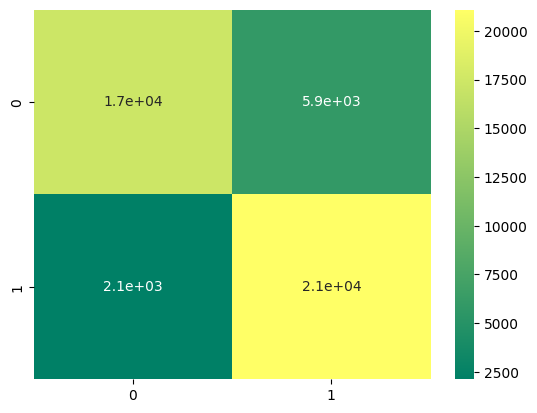

In [30]:
y_act=y_test
y_pred=model5.predict(X_test)
sns.heatmap(confusion_matrix(y_act,y_pred),annot=True,cmap='summer')
print(classification_report(y_act,y_pred))

# For multi-class classification
accuracy = accuracy_score(y_act, y_pred)
precision = precision_score(y_act, y_pred, average='weighted')
recall = recall_score(y_act, y_pred, average='weighted')

# Or for macro average (treats all classes equally)
precision_macro = precision_score(y_act, y_pred, average='macro')
recall_macro = recall_score(y_act, y_pred, average='macro')
f1score = f1_score(y_act, y_pred, average='macro')

print("\nAUC (Binary): {:.10f}".format(auc))

print("\n========== Model Performance ==========")
print("Accuracy:        {:.10f}".format(accuracy))
print("Precision:       {:.10f}".format(precision))
print("Recall:          {:.10f}".format(recall))
print("Precision Macro: {:.10f}".format(precision_macro))
print("Recall Macro:    {:.10f}".format(recall_macro))
print("F1 Score Macro:  {:.10f}".format(f1score))